# Modul 2 — Penanganan Missing Data

**Praktikum Data Wrangling (SD25-20007) · Program Studi Sains Data ITERA**

> **Starter versi 2026.2.** Menggantikan `02_missing.ipynb` versi awal, yang gagal membuat grafik di
> kernel Workbench macOS dan menyimpan keluaran di folder lain. Kerjakan di notebook ini; berkas
> lama boleh dihapus atau disimpan sebagai cadangan.

Workbench menyimpan notebook ini di laptop sebagai **`dw-module-02/02_missing_v2.ipynb`**; seluruh keluaran
modul juga ditulis ke folder `dw-module-02/` itu.
Dataset tidak perlu diunduh: tekan **Siapkan dataset di laptop** pada panel *Dataset di laptop*
halaman modul (Local Runner menyala), dan `data/raw/` terbentuk di akar workspace. Buku ajar: Bab 4.1–4.5.

| Bagian | Isi notebook ini | Dinilai? |
|---|---|---|
| A–D Prosedur terbimbing | **kode lengkap dan pembahasan** | dijalankan dan lulus checkpoint |
| Latihan 2.1–2.2 | kerangka `TODO` | **ya** — *Latihan Mandiri di Lab* (20% nilai modul) |
| Tugas Individu | kerangka `TODO` | **ya** — *Tugas Individu* (80% nilai modul) |

Bagian A–D bukan untuk disalin tanpa dibaca. Latihan dan tugas memakai **cara berpikir yang
sama** pada data lain (sensor gudang, rating toko), dan pertanyaan analisis menanyakan
alasan di balik setiap langkah A–D.

**Aturan main**
1. `data/raw/` bersifat *read-only* — jangan pernah menulis ke sana.
2. Jangan menghapus baris. Kekosongan diberi status, bukan dibuang.
3. Nilai yang teramati tidak boleh ikut berubah; pemeriksa membandingkannya sel demi sel.
4. Setiap perubahan data dicatat pada `log-keputusan.csv` di akar workspace.
5. Sebelum mengumpulkan: *Kernel → Restart Kernel and Run All Cells*, lalu jalankan Checkpoint.

## Bagian A — Mengungkap nilai hilang yang tersamar

### A.1 Menyiapkan notebook

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib

# Kernel DSWorkbench menjalankan sel di luar thread utama, sehingga backend GUI
# (mis. "macosx") gagal membuat figure. Di luar Jupyter/ipykernel dipakai Agg;
# figure yang terbuka tetap ditampilkan kernel sebagai gambar di bawah sel.
if "ipykernel" not in sys.modules:
    import warnings
    matplotlib.use("Agg")
    warnings.filterwarnings("ignore", message=r"FigureCanvas\w* is non-interactive")
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data" / "raw").is_dir())
RAW = ROOT / "data" / "raw"
MODUL = ROOT / "dw-module-02"      # folder tempat Workbench menyimpan notebook ini
OUT = MODUL / "keluaran"
OUT.mkdir(parents=True, exist_ok=True)
LOG = ROOT / "log-keputusan.csv"
SEED = 2026
pd.set_option("display.width", 140)

mentah = pd.read_csv(RAW / "transaksi.csv", dtype=str, keep_default_na=False)
status_bersih = mentah.status.str.lower()   # hanya untuk menentukan "berlaku"; kolom status tidak diubah
print("Akar repositori :", ROOT.name)
print("pandas          :", pd.__version__)
print("transaksi       :", mentah.shape)

Akar repositori : data-wrangling
pandas          : 3.0.5
transaksi       : (24288, 18)


### A.2 Kamus penanda dan fungsi pengungkap

In [2]:
PENANDA = {
    # kolom: penanda teks, penanda angka, dan pada baris mana kolom itu berlaku
    "ongkir": {
        "teks": ["-"], "angka": [],
        "berlaku": pd.Series(True, index=mentah.index),
    },
    "lama_kirim_hari": {
        "teks": [], "angka": [999, -1],
        "berlaku": status_bersih.isin(["selesai", "dikembalikan"]),
    },
    "rating_ulasan": {
        "teks": [], "angka": [0],
        "berlaku": status_bersih.eq("selesai"),
    },
}


def ungkap(teks: pd.Series, teks_penanda: list, angka: list, berlaku: pd.Series):
    """Ubah sel kosong dan penanda menjadi NaN, lalu beri status pada setiap sel.

    Status: teramati, kosong (sel kosong), penanda (token teks atau angka yang
    berarti "tidak diketahui"), atau tidak_berlaku (kolom memang tidak berlaku
    pada baris itu menurut kamus data).
    """
    kosong = teks.str.strip().eq("")
    penanda_teks = teks.isin(teks_penanda)
    # errors="raise": token yang belum dikenal harus menghentikan notebook,
    # bukan lenyap diam-diam menjadi NaN seperti errors="coerce".
    nilai = pd.to_numeric(teks.mask(kosong | penanda_teks), errors="raise")
    penanda = penanda_teks | nilai.isin(angka)
    nilai = nilai.mask(penanda)
    if (nilai.notna() & ~berlaku).any():
        raise ValueError(f"{teks.name}: ada nilai pada baris yang tidak berlaku")
    status = pd.Series(np.select([~berlaku, nilai.notna(), penanda],
                                 ["tidak_berlaku", "teramati", "penanda"], "kosong"),
                       index=teks.index)
    return nilai, status


t = mentah.copy()
for kolom, aturan in PENANDA.items():
    t[kolom], t[f"{kolom}_status"] = ungkap(mentah[kolom], aturan["teks"], aturan["angka"], aturan["berlaku"])

# id_pelanggan kosong di web = pembelian tamu yang diizinkan kamus data
tamu = mentah.id_pelanggan.eq("") & mentah.kanal.eq("web")
assert not (mentah.id_pelanggan.eq("") & mentah.kanal.eq("app")).any()
t["id_pelanggan"] = mentah.id_pelanggan.mask(tamu)
t["id_pelanggan_status"] = np.where(tamu, "tidak_berlaku", "teramati")

In [3]:
def rekonsiliasi(t: pd.DataFrame, kolom: list[str]) -> pd.DataFrame:
    baris = []
    for k in kolom:
        s = t[f"{k}_status"]
        n = s.value_counts()
        berlaku = int((s != "tidak_berlaku").sum())
        hilang = int(n.get("kosong", 0) + n.get("penanda", 0))
        baris.append({
            "kolom": k, "baris": len(s), "teramati": int(n.get("teramati", 0)),
            "kosong": int(n.get("kosong", 0)), "penanda": int(n.get("penanda", 0)),
            "tidak_berlaku": int(n.get("tidak_berlaku", 0)), "berlaku": berlaku,
            "hilang": hilang,
            "persen_hilang_dari_berlaku": round(100 * hilang / berlaku, 2),
            "persen_hilang_dari_semua": round(100 * hilang / len(s), 2),
        })
    return pd.DataFrame(baris)


rekon = rekonsiliasi(t, ["ongkir", "lama_kirim_hari", "rating_ulasan", "id_pelanggan"])
assert (rekon[["teramati", "kosong", "penanda", "tidak_berlaku"]].sum(axis=1) == len(t)).all()
rekon.to_csv(OUT / "rekonsiliasi_nilai_hilang.csv", index=False)
rekon

,kolom,baris,teramati,kosong,penanda,tidak_berlaku,berlaku,hilang,persen_hilang_dari_berlaku,persen_hilang_dari_semua
0,ongkir,24288,23177,1075,36,0,24288,1111,4.57,4.57
1,lama_kirim_hari,24288,20922,0,127,3239,21049,127,0.60,0.52
2,rating_ulasan,24288,13987,3280,2805,4216,20072,6085,30.32,25.05
3,id_pelanggan,24288,23870,0,0,418,23870,0,0.00,0.00


**Pembahasan A.2**

| Kolom | Kosong | Penanda | Tidak berlaku | Hilang | % dari baris berlaku |
|---|---:|---:|---:|---:|---:|
| `ongkir` | 1.075 | 36 (`"-"`) | 0 | 1.111 | 4,57 |
| `lama_kirim_hari` | 0 | 127 (92 × `999`, 35 × `-1`) | 3.239 | 127 | 0,60 |
| `rating_ulasan` | 3.280 (seluruhnya web) | 2.805 (`0`, seluruhnya app) | 4.216 | 6.085 | 30,32 |
| `id_pelanggan` | 0 | 0 | 418 (tamu web) | 0 | 0 |

- **2.968 sel tampak berisi tetapi sebenarnya hilang** (36 + 127 + 2.805). Pembacaan bawaan pandas
  hanya melihat sel kosong.
- Sebaliknya **7.873 sel kosong bukan nilai hilang**: lama kirim dan rating memang tidak ada pada
  pesanan yang dibatalkan/diproses, dan pembelian tamu memang tanpa `id_pelanggan`.
- `"-"` diberi status `penanda`, bukan `kosong`, karena asal-usulnya berbeda — ia hanya ditulis
  satu kurir (lihat C.1).
- `errors="raise"` sengaja dipakai: token baru harus menghentikan notebook, bukan diam-diam menjadi NaN.

## Bagian B — Profil dan pola kekosongan

### B.1 Matriks indikator dan laju kehilangan (Persamaan 4.1–4.3)

In [4]:
KOLOM_M = ["ongkir", "lama_kirim_hari", "rating_ulasan"]
# R = 1 bila teramati, 0 bila hilang; sel tidak berlaku dikeluarkan dari penyebut
R = pd.DataFrame({k: t[f"{k}_status"].eq("teramati").astype(int) for k in KOLOM_M})
berlaku = pd.DataFrame({k: t[f"{k}_status"].ne("tidak_berlaku") for k in KOLOM_M})

laju = pd.DataFrame({
    "p_j_naif (penyebut semua baris)": (1 - R).mean().round(4),
    "p_j_benar (penyebut baris berlaku)": ((1 - R) * berlaku).sum().div(berlaku.sum()).round(4),
})
laju.loc["keseluruhan"] = [
    round(float((1 - R).values.mean()), 4),
    round(float(((1 - R) * berlaku).values.sum() / berlaku.values.sum()), 4),
]
laju

,p_j_naif (penyebut semua baris),p_j_benar (penyebut baris berlaku)
ongkir,0.0457,0.0457
lama_kirim_hari,0.1386,0.0060
rating_ulasan,0.4241,0.3032
keseluruhan,0.2028,0.1120


### B.2 Pola kekosongan

In [5]:
# pola per baris, hanya sel yang berlaku: 1 = hilang
pola = pd.DataFrame({k: np.where(berlaku[k], 1 - R[k], -1) for k in KOLOM_M})
label = pola.replace({-1: "·", 0: "o", 1: "X"}).agg("".join, axis=1)
print("urutan kolom:", KOLOM_M, " (o teramati, X hilang, · tidak berlaku)")
print(label.value_counts().to_string())

urutan kolom: ['ongkir', 'lama_kirim_hari', 'rating_ulasan']  (o teramati, X hilang, · tidak berlaku)
ooo    13241
ooX     5787
o··     3096
oo·      931
Xoo      658
XoX      262
X··      143
oXo       84
Xo·       43
oXX       35
XXo        4
oX·        3
XXX        1


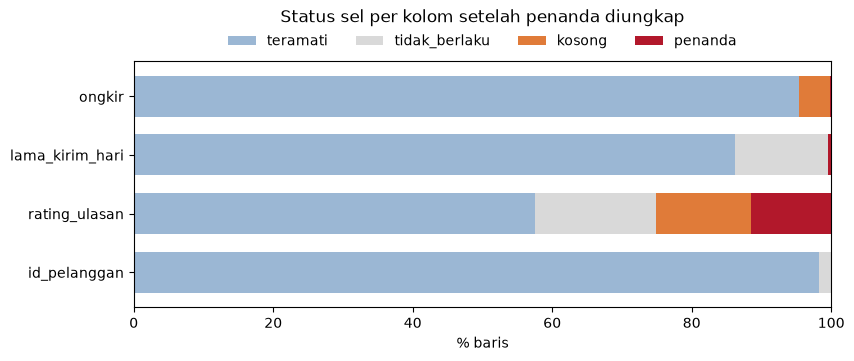

In [6]:
urut = ["teramati", "tidak_berlaku", "kosong", "penanda"]
warna = {"teramati": "#9bb7d4", "tidak_berlaku": "#d9d9d9", "kosong": "#e07b39", "penanda": "#b2182b"}
komposisi = pd.DataFrame({k: t[f"{k}_status"].value_counts(normalize=True).mul(100)
                          for k in ["ongkir", "lama_kirim_hari", "rating_ulasan", "id_pelanggan"]}).T
komposisi = komposisi.reindex(columns=urut).fillna(0)
ax = komposisi.plot(kind="barh", stacked=True, figsize=(9, 3.2), width=.7,
                    color=[warna[c] for c in urut])
ax.set_xlabel("% baris"); ax.invert_yaxis()
ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(.5, 1.0), frameon=False)
ax.set_title("Status sel per kolom setelah penanda diungkap", pad=28)
ax.get_figure().savefig(OUT / "01_komposisi_status_sel.png", dpi=120, bbox_inches="tight")
plt.show()

**Pembahasan B**

| | Penyebut semua baris | Penyebut baris berlaku |
|---|---:|---:|
| `ongkir` | 4,57% | 4,57% |
| `lama_kirim_hari` | 13,86% | **0,60%** |
| `rating_ulasan` | 42,41% | **30,32%** |
| keseluruhan (Pers. 4.3) | 20,28% | 11,20% |

- Penyebut yang salah membesar-besarkan kehilangan lama kirim **23 kali lipat**: pesanan yang
  dibatalkan dihitung seolah pengirimannya tidak tercatat.
- Pola keseluruhan **arbitrer** (ada `XoX`, `XXo`, `XXX`). Kekosongan strukturalnya sendiri
  **monoton**: bila lama kirim tidak berlaku, rating juga tidak berlaku.
- Grafik 01: hampir separuh kehilangan rating berupa **penanda** (merah), sehingga tidak terlihat
  pada grafik `missingno` Modul 1.

## Bagian C — Menguji mekanisme kekosongan

### C.1 Ongkos kirim

gagal diurai: 0
hari kanal app dengan >50% ongkir hilang: 2025-09-01 s.d. 2025-10-15 (45 hari)


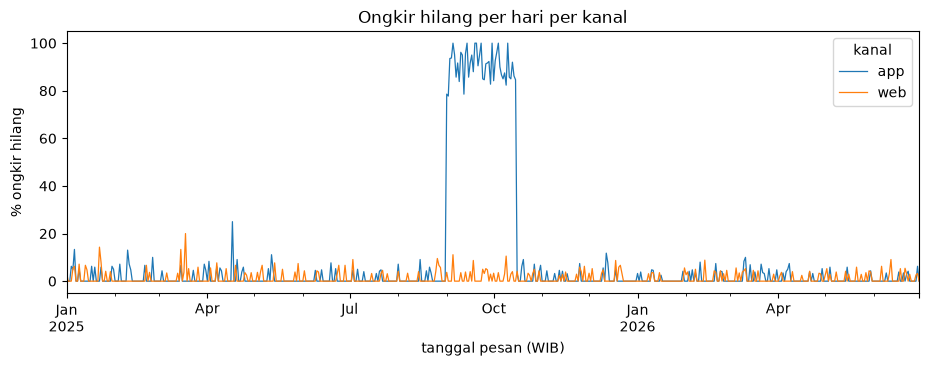

In [7]:
def waktu_wib(teks: pd.Series) -> pd.Series:
    """Hanya untuk analisis. Kolom waktu_pesan tidak diubah; itu pekerjaan Modul 4.

    Kanal app menulis waktu UTC berakhiran Z (temuan Modul 1), sehingga ditambah 7 jam.
    """
    spasi = pd.to_datetime(teks, format="%Y-%m-%d %H:%M:%S", errors="coerce")
    utc = pd.to_datetime(teks, format="%Y-%m-%dT%H:%M:%SZ", errors="coerce") + pd.Timedelta(hours=7)
    dmy = pd.to_datetime(teks, format="%d/%m/%Y %H:%M", errors="coerce")
    return spasi.fillna(utc).fillna(dmy)


waktu = waktu_wib(t.waktu_pesan)
print("gagal diurai:", int(waktu.isna().sum()))
sah = waktu.between("2025-01-01", "2026-06-30 23:59:59")   # buang 1970 dan 2062 dari grafik
ongkir_hilang = t.ongkir_status.ne("teramati")

harian = (ongkir_hilang[sah].groupby([waktu[sah].dt.floor("D"), t.kanal[sah]])
          .mean().unstack().mul(100))
fig, ax = plt.subplots(figsize=(11, 3.4))
harian.plot(ax=ax, lw=.9)
ax.set_ylabel("% ongkir hilang"); ax.set_xlabel("tanggal pesan (WIB)")
ax.set_title("Ongkir hilang per hari per kanal")
fig.savefig(OUT / "02_ongkir_hilang_harian.png", dpi=120, bbox_inches="tight")
plt.show()

tinggi = harian["app"][harian["app"] > 50]
print("hari kanal app dengan >50% ongkir hilang:", tinggi.index.min().date(), "s.d.",
      tinggi.index.max().date(), f"({len(tinggi)} hari)")

In [8]:
jendela = (t.kanal.eq("app") & waktu.ge("2025-09-01") & waktu.lt("2025-10-16"))

def uji_chi2(mask_hilang: pd.Series, grup: pd.Series) -> dict:
    tabel = pd.crosstab(grup, mask_hilang)
    r = stats.chi2_contingency(tabel)
    return {"chi2": round(float(r.statistic), 2), "dof": int(r.dof), "p": round(float(r.pvalue), 4)}


def pct(x: float, d: int = 1) -> str:
    """Angka berformat Indonesia untuk teks bukti: 90.66 -> '90,7'."""
    return f"{x:.{d}f}".replace(".", ",")


B = {}   # angka bukti yang dipakai ulang pada tabel mekanisme dan log keputusan

print("Seluruh data  | hilang vs kanal:", uji_chi2(ongkir_hilang, t.kanal))
print(f"Di jendela    : {int(jendela.sum())} baris app, {int((ongkir_hilang & jendela).sum())} hilang "
      f"({100 * ongkir_hilang[jendela].mean():.1f}%)")
print(f"               = {100 * (ongkir_hilang & jendela).sum() / ongkir_hilang.sum():.1f}% dari seluruh ongkir hilang")
luar = ~jendela
B["ong_jendela"] = 100 * ongkir_hilang[jendela].mean()
B["ong_porsi_jendela"] = 100 * (ongkir_hilang & jendela).sum() / ongkir_hilang.sum()
B["ong_luar"] = 100 * ongkir_hilang[luar].mean()
print(f"Di luar jendela: {int((ongkir_hilang & luar).sum())} hilang ({100 * ongkir_hilang[luar].mean():.2f}%)")
kosong_luar = t.ongkir_status.eq("kosong")
uji_luar = {g: uji_chi2(kosong_luar[luar], t.loc[luar, g])
            for g in ["kanal", "kurir", "provinsi_tujuan", "status"]}
for g, r in uji_luar.items():
    print(f"  luar jendela, kosong vs {g:<16}", r)
B["ong_luar_p_min"] = min(r["p"] for r in uji_luar.values())
tb = pd.to_numeric(t.total_bayar)
print("  luar jendela, total_bayar kosong vs teramati, Mann-Whitney p =",
      round(stats.mannwhitneyu(tb[luar & kosong_luar], tb[luar & ~ongkir_hilang]).pvalue, 4))
print("\nToken '-' per kurir:", t.loc[t.ongkir_status.eq("penanda"), "kurir"].value_counts().to_dict())
print("Token '-' vs kurir  :", uji_chi2(t.ongkir_status.eq("penanda"), t.kurir))

Seluruh data  | hilang vs kanal: {'chi2': 752.94, 'dof': 1, 'p': 0.0}
Di jendela    : 924 baris app, 838 hilang (90.7%)
               = 75.4% dari seluruh ongkir hilang
Di luar jendela: 273 hilang (1.17%)
  luar jendela, kosong vs kanal            {'chi2': 0.0, 'dof': 1, 'p': 0.9859}
  luar jendela, kosong vs kurir            {'chi2': 1.63, 'dof': 4, 'p': 0.8029}
  luar jendela, kosong vs provinsi_tujuan  {'chi2': 14.47, 'dof': 19, 'p': 0.7558}
  luar jendela, kosong vs status           {'chi2': 7.46, 'dof': 7, 'p': 0.383}
  luar jendela, total_bayar kosong vs teramati, Mann-Whitney p = 0.6964

Token '-' per kurir: {'Pos Indonesia': 36}
Token '-' vs kurir  : {'chi2': 142.84, 'dof': 4, 'p': 0.0}


**Pembahasan C.1**

- Kehilangan menumpuk pada **kanal app, 1 September–15 Oktober 2025 WIB**: 838 dari 924 baris
  (90,7%), yaitu 75,4% dari seluruh ongkir yang hilang. Kanal web pada periode yang sama tetap 1–2%.
- **Di luar jendela** kehilangan 1,17% dan tidak berhubungan dengan kanal, kurir, provinsi, status,
  maupun besar `total_bayar` (seluruh p ≥ 0,38) — konsisten dengan MCAR.
- Token `"-"`: 36 baris, seluruhnya Pos Indonesia — bergantung pada variabel teramati (kurir), MAR.
- Kesimpulan: **MAR** menurut kanal dan waktu, ditambah sisa yang konsisten dengan MCAR.
- Grafik hanya menunjukkan *kapan* dan *di mana*. "Karena aplikasi rusak" adalah hipotesis; cara
  mengujinya misalnya mencocokkan tanggal dengan catatan rilis aplikasi atau bertanya pada tim
  operasional.

### C.2 Rating ulasan

In [9]:
selesai = t.rating_ulasan_status.ne("tidak_berlaku")
rating_hilang = t.rating_ulasan_status.isin(["kosong", "penanda"])
sebelum = mentah.rating_ulasan.eq("")      # yang tampak hilang sebelum penanda diungkap
print("% rating hilang di antara pesanan selesai, per kanal")
print(pd.DataFrame({
    "sebelum_penanda_diungkap": sebelum[selesai].groupby(t.kanal[selesai]).mean().mul(100).round(2),
    "sesudah_penanda_diungkap": rating_hilang[selesai].groupby(t.kanal[selesai]).mean().mul(100).round(2),
}))
B["rat_kanal"] = rating_hilang[selesai].groupby(t.kanal[selesai]).mean().mul(100).to_dict()
B["rat_kanal_p"] = uji_chi2(rating_hilang[selesai], t.kanal[selesai])["p"]
print("\nUji kanal sesudah diungkap: p =", B["rat_kanal_p"])

% rating hilang di antara pesanan selesai, per kanal
       sebelum_penanda_diungkap  sesudah_penanda_diungkap
kanal                                                    
app                         0.0                     30.58
web                        30.1                     30.10

Uji kanal sesudah diungkap: p = 0.4721


          pesanan  persen_rating_hilang  rata_rating_teramati
kelompok                                                     
1-2          9413                  29.7                 4.289
3            4783                  28.6                 4.302
4            3022                  30.4                 4.277
5            1493                  31.2                 4.124
6-7           895                  35.3                 3.808
8-30          342                  54.4                 2.968

hilang vs kelompok lama kirim: {'chi2': 113.4, 'dof': 5, 'p': 0.0}
lama kirim rata-rata: rating hilang 3.25 hari, rating teramati 2.91 hari, Mann-Whitney p = 1.40e-04


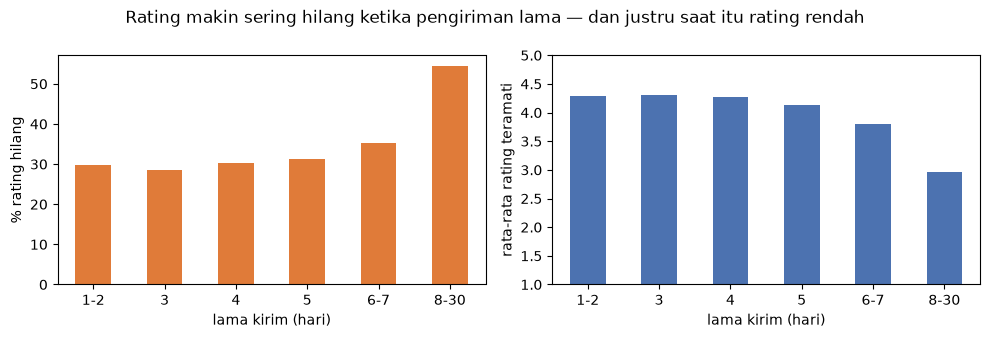

In [10]:
lama = t.lama_kirim_hari
kelompok = pd.cut(lama, [0, 2, 3, 4, 5, 7, 30], labels=["1-2", "3", "4", "5", "6-7", "8-30"])
d = pd.DataFrame({"hilang": rating_hilang, "kelompok": kelompok, "rating": t.rating_ulasan})[selesai]
per_lama = d.groupby("kelompok", observed=True).agg(
    pesanan=("hilang", "size"),
    persen_rating_hilang=("hilang", lambda s: round(100 * s.mean(), 1)),
    rata_rating_teramati=("rating", lambda s: round(s.mean(), 3)))
print(per_lama)
B["rat_laju"] = per_lama.persen_rating_hilang
B["rat_rata"] = per_lama.rata_rating_teramati
print("\nhilang vs kelompok lama kirim:", uji_chi2(d.hilang, d.kelompok))
a, b = lama[selesai & rating_hilang].dropna(), lama[selesai & ~rating_hilang].dropna()
print(f"lama kirim rata-rata: rating hilang {a.mean():.2f} hari, rating teramati {b.mean():.2f} hari, "
      f"Mann-Whitney p = {stats.mannwhitneyu(a, b).pvalue:.2e}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
per_lama.persen_rating_hilang.plot(kind="bar", ax=ax1, color="#e07b39", rot=0)
ax1.set_ylabel("% rating hilang"); ax1.set_xlabel("lama kirim (hari)")
per_lama.rata_rating_teramati.plot(kind="bar", ax=ax2, color="#4c72b0", rot=0)
ax2.set_ylabel("rata-rata rating teramati"); ax2.set_xlabel("lama kirim (hari)"); ax2.set_ylim(1, 5)
fig.suptitle("Rating makin sering hilang ketika pengiriman lama — dan justru saat itu rating rendah")
fig.tight_layout()
fig.savefig(OUT / "03_rating_hilang_lama_kirim.png", dpi=120, bbox_inches="tight")
plt.show()

**Pembahasan C.2**

| Kanal | % rating hilang sebelum penanda diungkap | sesudah |
|---|---:|---:|
| app | 0,00 | 30,58 |
| web | 30,10 | 30,10 |

- Kanal app tampak tidak pernah kehilangan rating — mustahil. Setelah 0 diungkap, laju kedua kanal
  setara (p = 0,47). Itulah bukti bahwa 0 adalah penanda.

| Lama kirim | 1–2 | 3 | 4 | 5 | 6–7 | 8–30 |
|---|---:|---:|---:|---:|---:|---:|
| % rating hilang | 29,7 | 28,6 | 30,4 | 31,2 | 35,3 | 54,4 |
| rata-rata rating teramati | 4,29 | 4,30 | 4,28 | 4,12 | 3,81 | 2,97 |

- Rating paling sering hilang justru ketika pengiriman lama, saat rating yang teramati paling rendah.
  Penjelasan paling masuk akal: pembeli yang kecewa cenderung tidak memberi rating — kekosongan
  bergantung pada nilai rating itu sendiri, yaitu **MNAR**.
- MNAR **tidak dapat dibuktikan** dari data teramati; hubungan dengan lama kirim hanya bukti tidak
  langsung. Karena itu rating tidak diimputasi, dan kesimpulan kepuasan dilaporkan dengan analisis
  sensitivitas (Tugas).

### C.3 Lama kirim

In [11]:
penanda_lama = t.lama_kirim_hari_status.eq("penanda")
berlaku_lama = t.lama_kirim_hari_status.ne("tidak_berlaku")
print("nilai penanda:", mentah.loc[penanda_lama, "lama_kirim_hari"].value_counts().to_dict())
uji_lama = {g: uji_chi2(penanda_lama[berlaku_lama], t.loc[berlaku_lama, g])
            for g in ["kurir", "kanal", "provinsi_tujuan"]}
for g, r in uji_lama.items():
    print(f"penanda vs {g:<16}", r)
B["lama_p_min"] = min(r["p"] for r in uji_lama.values())
print("persen penanda per kanal:", penanda_lama[berlaku_lama].groupby(t.kanal[berlaku_lama]).mean().mul(100).round(2).to_dict())

nilai penanda: {'999.0': 92, '-1.0': 35}
penanda vs kurir            {'chi2': 6.38, 'dof': 4, 'p': 0.1727}
penanda vs kanal            {'chi2': 0.92, 'dof': 1, 'p': 0.3366}
penanda vs provinsi_tujuan  {'chi2': 16.98, 'dof': 19, 'p': 0.5911}
persen penanda per kanal: {'app': 0.66, 'web': 0.55}


In [12]:
r = rekon.set_index("kolom")
mekanisme = pd.DataFrame([
    {"kolom": "ongkir", "mekanisme": "MAR",
     "bukti": (f"hilang {pct(B['ong_jendela'])}% pada kanal app 1 Sep-15 Okt 2025 "
               f"({pct(B['ong_porsi_jendela'])}% dari seluruh kekosongan); di luar jendela "
               f"{pct(B['ong_luar'], 2)}% tanpa hubungan dengan kanal, kurir, provinsi, status "
               f"(chi2 p>={pct(B['ong_luar_p_min'], 2)}); token '-' seluruhnya Pos Indonesia"),
     "catatan": "MAR menurut kanal dan waktu, sisanya konsisten dengan MCAR; token '-' MAR menurut kurir",
     "keputusan": "imputasi deduktif dari total_bayar, sisanya median per provinsi_tujuan; kolom ongkir_metode"},
    {"kolom": "lama_kirim_hari", "mekanisme": "MCAR",
     "bukti": (f"{r.loc['lama_kirim_hari', 'penanda']} penanda (999 dan -1) = "
               f"{pct(r.loc['lama_kirim_hari', 'persen_hilang_dari_berlaku'], 2)}% baris berlaku; "
               f"tidak berhubungan dengan kurir, kanal, provinsi (chi2 p>={pct(B['lama_p_min'], 2)})"),
     "catatan": (f"konsisten dengan MCAR; {r.loc['lama_kirim_hari', 'tidak_berlaku']:,} kosong adalah "
                 "struktural (status dibatalkan/diproses)").replace(",", "."),
     "keputusan": "penanda menjadi NaN, tidak diimputasi; analisis memakai kasus tersedia"},
    {"kolom": "rating_ulasan", "mekanisme": "MNAR",
     "bukti": (f"setelah 0 diungkap, laju hilang app {pct(B['rat_kanal']['app'], 2)}% vs web "
               f"{pct(B['rat_kanal']['web'], 2)}% (p={pct(B['rat_kanal_p'], 2)}); laju hilang naik dari "
               f"{pct(B['rat_laju'].iloc[0])}% (1-2 hari) ke {pct(B['rat_laju'].iloc[-1])}% (8-30 hari) "
               f"sementara rating teramati turun {pct(B['rat_rata'].iloc[0], 2)} ke {pct(B['rat_rata'].iloc[-1], 2)}"),
     "catatan": "dugaan, tidak dapat dibuktikan dari data; kekosongan terkait kepuasan yang tidak teramati",
     "keputusan": "tidak diimputasi; laporkan kasus lengkap disertai analisis sensitivitas"},
])
mekanisme.to_csv(OUT / "mekanisme_nilai_hilang.csv", index=False)
mekanisme[["kolom", "mekanisme", "keputusan"]]

,kolom,mekanisme,keputusan
0,ongkir,MAR,"imputasi deduktif dari total_bayar, sisanya me..."
1,lama_kirim_hari,MCAR,"penanda menjadi NaN, tidak diimputasi; analisi..."
2,rating_ulasan,MNAR,tidak diimputasi; laporkan kasus lengkap diser...


**Pembahasan C.3 dan tabel mekanisme**

- 127 penanda (92 × `999` + 35 × `-1`) tidak berhubungan dengan kurir, kanal, atau provinsi —
  konsisten dengan **MCAR**. Lama kirim 18–30 hari (Modul 1) adalah nilai sah dan tidak disentuh.

| Kolom | Mekanisme | Keputusan |
|---|---|---|
| `ongkir` | MAR (kanal × waktu; `"-"` menurut kurir) + sisa MCAR | imputasi deduktif, cadangan median per provinsi |
| `lama_kirim_hari` | MCAR | tidak diimputasi |
| `rating_ulasan` | MNAR (dugaan) | tidak diimputasi, analisis sensitivitas |

## Bagian D — Menangani dan mengevaluasi

### D.1 Harga sebuah `dropna()`

In [13]:
n = len(t)
cc = t.dropna(subset=KOLOM_M)
print(f"dropna(subset=3 kolom): {len(cc):,} dari {n:,} baris tersisa ({100 * (n - len(cc)) / n:.2f}% hilang)")
print("status yang tersisa:", cc.status.str.lower().value_counts().to_dict())

bulan = waktu.dt.strftime("%Y-%m")
porsi_app = pd.DataFrame({
    "semua_baris": t.kanal.eq("app").groupby(bulan).mean(),
    "setelah_dropna_ongkir": t.kanal[~ongkir_hilang].eq("app").groupby(bulan[~ongkir_hilang]).mean(),
}).mul(100).round(1)
print("\n% baris kanal app per bulan")
print(porsi_app.loc["2025-08":"2025-11"])
app_sep = t.kanal.eq("app") & bulan.eq("2025-09")
print(f"\ntotal_bayar app Sep 2025: semua Rp{tb[app_sep].sum():,.0f}; "
      f"setelah dropna ongkir Rp{tb[app_sep & ~ongkir_hilang].sum():,.0f}")

dropna(subset=3 kolom): 13,241 dari 24,288 baris tersisa (45.48% hilang)
status yang tersisa: {'selesai': 13241}

% baris kanal app per bulan
             semua_baris  setelah_dropna_ongkir
waktu_pesan                                    
2025-08             48.6                   48.8
2025-09             45.7                    6.9
2025-10             41.8                   29.0
2025-11             45.5                   45.5

total_bayar app Sep 2025: semua Rp278,068,850; setelah dropna ongkir Rp25,613,950


### D.2 Mengevaluasi metode imputasi dengan menyembunyikan nilai yang diketahui

In [14]:
from sklearn.impute import SimpleImputer

num = mentah[["jumlah", "harga_satuan", "diskon_persen", "total_bayar"]].apply(pd.to_numeric)
ongkir = t.ongkir
print("ongkir teramati kelipatan Rp500:", f"{100 * (ongkir.dropna() % 500 == 0).mean():.2f}%")

# Imputasi deduktif: total_bayar = subtotal + ongkir  =>  ongkir = total_bayar - subtotal
subtotal = num.jumlah * num.harga_satuan * (1 - num.diskon_persen / 100)
turunan = num.total_bayar - subtotal
prasyarat = num.jumlah.ge(1) & ~num.diskon_persen.between(0, 1, inclusive="neither")
deduktif_sah = prasyarat & turunan.ge(0) & turunan.round().mod(500).eq(0)

rng = np.random.default_rng(SEED)
diketahui = ongkir.dropna().index
uji = pd.Index(rng.choice(diketahui, size=int(.10 * len(diketahui)), replace=False))
latih = ongkir.copy()
latih[uji] = np.nan                                    # nilai yang "disembunyikan"

med_prov = latih.groupby(t.provinsi_tujuan).transform("median").fillna(latih.median())
kandidat = {
    "rata_rata_global": pd.Series(SimpleImputer(strategy="mean")
                                  .fit_transform(latih.to_frame()).ravel(), index=t.index),
    "median_global":    pd.Series(SimpleImputer(strategy="median")
                                  .fit_transform(latih.to_frame()).ravel(), index=t.index),
    "median_provinsi":  med_prov,
    "deduktif_lalu_median_provinsi": turunan.where(deduktif_sah).fillna(med_prov),
}
benar = ongkir[uji]
evaluasi = []
for nama, isian in kandidat.items():
    galat = isian[uji] - benar
    terisi = latih.fillna(isian)
    evaluasi.append({
        "metode": nama, "n_uji": len(uji),
        "MAE": round(galat.abs().mean(), 1), "median_galat_absolut": round(galat.abs().median(), 1),
        "bias": round(galat.mean(), 1), "persen_tepat": round(100 * (galat.abs() <= 1).mean(), 2),
        "rasio_sd": round(terisi.std() / ongkir.std(), 3),
    })
evaluasi = pd.DataFrame(evaluasi)
evaluasi.to_csv(OUT / "evaluasi_imputasi_ongkir.csv", index=False)
evaluasi

ongkir teramati kelipatan Rp500: 100.00%


,metode,n_uji,MAE,median_galat_absolut,bias,persen_tepat,rasio_sd
0,rata_rata_global,2317,9355.9,6159.4,544.4,0.00,0.928
1,median_global,2317,7110.5,2500.0,-4615.0,0.35,0.931
2,median_provinsi,2317,5724.4,0.0,-5724.4,73.20,0.932
3,deduktif_lalu_median_provinsi,2317,140.1,0.0,-19.2,98.83,1.007


In [15]:
print("deduktif sah pada baris uji      :", f"{100 * deduktif_sah[uji].mean():.2f}%")
galat_d = (turunan - ongkir)[deduktif_sah & ongkir.notna()]
print("galat deduktif pada baris teramati:", galat_d.round(-2).value_counts().head(4).to_dict())

deduktif sah pada baris uji      : 97.37%
galat deduktif pada baris teramati: {0.0: 22426, 10000.0: 114}


Pembahasan D.1–D.4 ada pada sel **Pembahasan D** di akhir Bagian D.

### D.3 Menerapkan keputusan

In [16]:
hasil = t.copy()
isi_deduktif = hasil.ongkir.isna() & deduktif_sah
med_prov_penuh = ongkir.groupby(t.provinsi_tujuan).transform("median").fillna(ongkir.median())
hasil.loc[isi_deduktif, "ongkir"] = turunan[isi_deduktif]
isi_median = hasil.ongkir.isna()
hasil.loc[isi_median, "ongkir"] = med_prov_penuh[isi_median]
hasil["ongkir_metode"] = np.select([isi_deduktif, isi_median], ["deduktif", "median_provinsi"], "teramati")

hasil["lama_kirim_hari"] = hasil.lama_kirim_hari.astype("Int64")
hasil["rating_ulasan"] = hasil.rating_ulasan.astype("Int64")
hasil["pembeli_tamu"] = tamu

print(hasil.ongkir_metode.value_counts().to_dict())
assert hasil.ongkir.notna().all() and len(hasil) == len(mentah)
# nilai yang teramati tidak boleh berubah
assert hasil.ongkir[t.ongkir_status.eq("teramati")].equals(ongkir[t.ongkir_status.eq("teramati")])

hasil.to_parquet(OUT / "transaksi_m02.parquet", index=False)
print(hasil.shape, "->", (OUT / "transaksi_m02.parquet").name)

{'teramati': 23177, 'deduktif': 1049, 'median_provinsi': 62}
(24288, 24) -> transaksi_m02.parquet


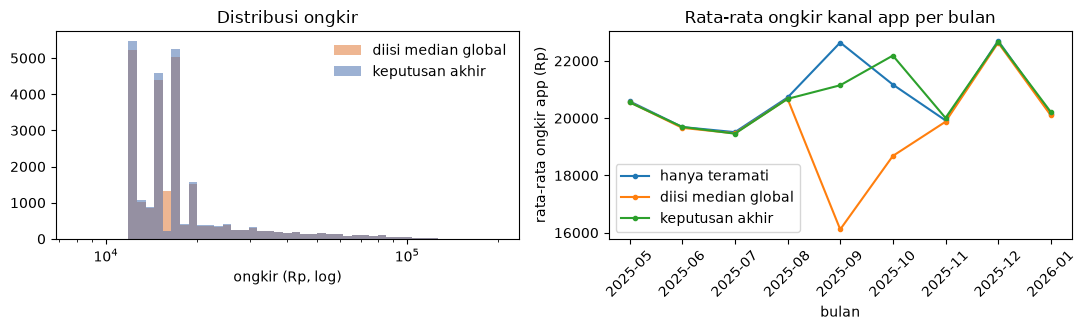

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.4))
alt = ongkir.fillna(ongkir.median())
bins = np.logspace(np.log10(8_000), np.log10(200_000), 50)
ax1.hist(alt, bins=bins, alpha=.55, label="diisi median global", color="#e07b39")
ax1.hist(hasil.ongkir, bins=bins, alpha=.55, label="keputusan akhir", color="#4c72b0")
ax1.set_xscale("log"); ax1.set_xlabel("ongkir (Rp, log)"); ax1.legend(frameon=False)
ax1.set_title("Distribusi ongkir")
app = t.kanal.eq("app") & sah
pd.DataFrame({
    "hanya teramati": ongkir[app].groupby(bulan[app]).mean(),
    "diisi median global": alt[app].groupby(bulan[app]).mean(),
    "keputusan akhir": hasil.ongkir[app].groupby(bulan[app]).mean(),
}).loc["2025-05":"2026-01"].plot(ax=ax2, marker=".")
ax2.set_ylabel("rata-rata ongkir app (Rp)"); ax2.set_xlabel("bulan")
ax2.tick_params(axis="x", rotation=45)
ax2.set_title("Rata-rata ongkir kanal app per bulan")
fig.tight_layout()
fig.savefig(OUT / "04_dampak_imputasi_ongkir.png", dpi=120, bbox_inches="tight")
plt.show()

### D.4 Log keputusan

In [18]:
import shutil

KOLOM_LOG = ["id", "modul", "sumber_kolom", "temuan", "bukti", "tindakan", "alasan",
             "baris_terdampak", "id_anomali"]


def catat_keputusan(baris: list[dict], path: Path = LOG) -> pd.DataFrame:
    """Tulis ulang baris log dengan id yang sama agar notebook aman dijalankan berulang."""
    lama = (pd.read_csv(path, dtype=str, keep_default_na=False) if path.exists()
            else pd.DataFrame(columns=KOLOM_LOG))
    baru = pd.DataFrame(baris, columns=KOLOM_LOG).astype(str)
    log = pd.concat([lama[~lama.id.isin(baru.id)], baru]).sort_values("id")
    log.to_csv(path, index=False)
    shutil.copyfile(path, MODUL / path.name)   # salinan untuk ZIP tugas
    return log


mc = hasil.ongkir_metode.value_counts()
ev = evaluasi.set_index("metode")
log = catat_keputusan([
    {"id": "K-02-001", "modul": 2, "sumber_kolom": "transaksi.ongkir",
     "temuan": "ongkir tidak dapat dipakai sebagai angka: sel kosong dan token '-'",
     "bukti": (f"kosong {r.loc['ongkir', 'kosong']}, token '-' {r.loc['ongkir', 'penanda']} (seluruhnya Pos Indonesia); "
               f"total {r.loc['ongkir', 'hilang']} baris ({pct(r.loc['ongkir', 'persen_hilang_dari_semua'], 2)}%)"),
     "tindakan": "kedua bentuk diubah menjadi NaN; asal-usulnya disimpan pada ongkir_status (kosong/penanda)",
     "alasan": "token '-' membuat kolom terbaca teks; keduanya sama-sama tidak diketahui nilainya",
     "baris_terdampak": int(r.loc["ongkir", "hilang"]), "id_anomali": "A-01;A-02"},
    {"id": "K-02-002", "modul": 2, "sumber_kolom": "transaksi.ongkir",
     "temuan": f"ongkir hilang MAR: {pct(B['ong_jendela'])}% pada kanal app 1 Sep-15 Okt 2025",
     "bukti": (f"uji sembunyi 10% ({len(uji)} baris): deduktif MAE Rp{ev.loc['deduktif_lalu_median_provinsi', 'MAE']:.0f}, "
               f"tepat {pct(ev.loc['deduktif_lalu_median_provinsi', 'persen_tepat'])}% vs median global MAE "
               f"Rp{ev.loc['median_global', 'MAE']:.0f}; rata-rata ongkir app Sep 2025 turun ke "
               f"Rp{alt[app & bulan.eq('2025-09')].mean():.0f} bila diisi median global"),
     "tindakan": "ongkir = total_bayar - jumlah*harga_satuan*(1-diskon_persen/100) bila jumlah>=1, diskon bukan pecahan, hasil >=0 dan kelipatan 500; ongkir_metode=deduktif",
     "alasan": "nilai dapat diturunkan dari identitas akuntansi; imputasi statistik mengecilkan ongkir app September",
     "baris_terdampak": int(mc.get("deduktif", 0)), "id_anomali": "A-01"},
    {"id": "K-02-003", "modul": 2, "sumber_kolom": "transaksi.ongkir",
     "temuan": "sisa ongkir hilang yang identitasnya tidak dapat dipercaya",
     "bukti": f"{int(mc.get('median_provinsi', 0))} baris gagal prasyarat (jumlah<1, diskon pecahan, atau hasil negatif/bukan kelipatan 500)",
     "tindakan": "diisi median ongkir teramati per provinsi_tujuan; ongkir_metode=median_provinsi",
     "alasan": "ongkir ditentukan jarak tujuan; median tahan terhadap kemiringan (skew ongkir >16)",
     "baris_terdampak": int(mc.get("median_provinsi", 0)), "id_anomali": "A-01"},
    {"id": "K-02-004", "modul": 2, "sumber_kolom": "transaksi.lama_kirim_hari",
     "temuan": "angka penanda 999 dan -1 pada lama kirim",
     "bukti": (f"{r.loc['lama_kirim_hari', 'penanda']} baris ({pct(r.loc['lama_kirim_hari', 'persen_hilang_dari_berlaku'], 2)}% "
               f"baris berlaku); chi2 terhadap kurir, kanal, provinsi p>={pct(B['lama_p_min'], 2)}"),
     "tindakan": "penanda menjadi NaN, lama_kirim_hari_status=penanda; tidak diimputasi",
     "alasan": "konsisten dengan MCAR dan kecil, sehingga analisis kasus tersedia tidak bias; imputasi hanya menambah kepastian palsu",
     "baris_terdampak": int(r.loc["lama_kirim_hari", "penanda"]), "id_anomali": "A-04"},
    {"id": "K-02-005", "modul": 2, "sumber_kolom": "transaksi.lama_kirim_hari;transaksi.rating_ulasan",
     "temuan": "kekosongan struktural: lama kirim dan rating tidak berlaku pada status tertentu",
     "bukti": (f"lama kirim kosong {r.loc['lama_kirim_hari', 'tidak_berlaku']} baris, seluruhnya dibatalkan/diproses; "
               f"rating kosong {r.loc['rating_ulasan', 'tidak_berlaku']} baris bukan status selesai"),
     "tindakan": "tetap NaN dengan <kolom>_status=tidak_berlaku; dikeluarkan dari penyebut laju kehilangan",
     "alasan": "nilai memang tidak ada, bukan tidak tercatat; mengisinya menciptakan pengiriman atau ulasan fiktif",
     "baris_terdampak": 0, "id_anomali": "-"},
    {"id": "K-02-006", "modul": 2, "sumber_kolom": "transaksi.rating_ulasan",
     "temuan": "kanal app menulis 0 untuk rating yang tidak diisi",
     "bukti": (f"{r.loc['rating_ulasan', 'penanda']} rating 0, seluruhnya app; laju hilang app 0% sebelum vs "
               f"{pct(B['rat_kanal']['app'], 2)}% sesudah diungkap, web {pct(B['rat_kanal']['web'], 2)}%"),
     "tindakan": "0 menjadi NaN, rating_ulasan_status=penanda",
     "alasan": f"skala 1-5; setelah diungkap laju kehilangan kedua kanal setara (chi2 p={pct(B['rat_kanal_p'], 2)})",
     "baris_terdampak": int(r.loc["rating_ulasan", "penanda"]), "id_anomali": "A-03"},
    {"id": "K-02-007", "modul": 2, "sumber_kolom": "transaksi.rating_ulasan",
     "temuan": "rating tidak diisi diduga MNAR",
     "bukti": (f"{r.loc['rating_ulasan', 'hilang']} baris ({pct(r.loc['rating_ulasan', 'persen_hilang_dari_berlaku'], 2)}% "
               f"pesanan selesai); laju hilang {pct(B['rat_laju'].iloc[0])}% (1-2 hari) naik ke "
               f"{pct(B['rat_laju'].iloc[-1])}% (8-30 hari)"),
     "tindakan": "tidak diimputasi; laporan kepuasan disertai analisis sensitivitas delta",
     "alasan": "median/mean mengasumsikan MCAR dan menambah rating 4 fiktif; bias tidak dapat dikoreksi tanpa asumsi tentang nilai yang hilang",
     "baris_terdampak": 0, "id_anomali": "A-03"},
    {"id": "K-02-008", "modul": 2, "sumber_kolom": "transaksi.id_pelanggan",
     "temuan": "id_pelanggan kosong pada pembelian tamu kanal web",
     "bukti": f"{int(tamu.sum())} baris, seluruhnya web; diizinkan kamus data",
     "tindakan": "string kosong menjadi NA, ditambah kolom pembeli_tamu; tidak diisi konstanta",
     "alasan": "konstanta 'TAMU' menciptakan satu pelanggan fiktif dengan pesanan terbanyak",
     "baris_terdampak": int(tamu.sum()), "id_anomali": "-"},
])
log[log.id.str.startswith("K-02")][["id", "sumber_kolom", "tindakan", "baris_terdampak"]]

,id,sumber_kolom,tindakan,baris_terdampak
0,K-02-001,transaksi.ongkir,kedua bentuk diubah menjadi NaN; asal-usulnya ...,1111
1,K-02-002,transaksi.ongkir,ongkir = total_bayar - jumlah*harga_satuan*(1-...,1049
2,K-02-003,transaksi.ongkir,diisi median ongkir teramati per provinsi_tuju...,62
3,K-02-004,transaksi.lama_kirim_hari,"penanda menjadi NaN, lama_kirim_hari_status=pe...",127
4,K-02-005,transaksi.lama_kirim_hari;transaksi.rating_ulasan,tetap NaN dengan <kolom>_status=tidak_berlaku;...,0
5,K-02-006,transaksi.rating_ulasan,"0 menjadi NaN, rating_ulasan_status=penanda",2805
6,K-02-007,transaksi.rating_ulasan,tidak diimputasi; laporan kepuasan disertai an...,0
7,K-02-008,transaksi.id_pelanggan,"string kosong menjadi NA, ditambah kolom pembe...",418


**Pembahasan D**

**D.1.** `dropna` pada tiga kolom menyisakan 13.241 dari 24.288 baris (45,48% hilang) dan
**hanya pesanan selesai**. Menghapus baris tanpa ongkir saja menurunkan porsi kanal app September
2025 dari 45,7% menjadi 6,9% — bias penghapusan pada data MAR.

**D.2.** Uji sembunyi 10% ongkir yang diketahui (2.317 baris):

| Metode | MAE (Rp) | Bias (Rp) | % tepat | rasio sd |
|---|---:|---:|---:|---:|
| rata-rata global | 9.356 | +544 | 0,0 | 0,928 |
| median global | 7.111 | −4.615 | 0,4 | 0,931 |
| median per provinsi | 5.724 | −5.724 | 73,2 | 0,932 |
| deduktif lalu median provinsi | **140** | **−19** | **98,8** | **1,007** |

- Kamus data Modul 1 menyatakan `total_bayar = subtotal + ongkir`, sehingga ongkir dapat
  **diturunkan**, bukan ditebak. Identitas itu hanya dipercaya bila `jumlah ≥ 1`, diskon bukan pecahan,
  dan hasilnya ≥ 0 serta kelipatan Rp500 (seluruh ongkir teramati kelipatan Rp500).
- Sisa galat: 114 baris teramati meleset tepat +Rp10.000 — anomali `total_bayar` Modul 1 yang tidak
  dapat dideteksi pada baris yang ongkirnya hilang. Itu risiko sisa yang harus ditulis.

**D.3.** 1.049 ongkir deduktif, 62 median provinsi. Grafik 04: mengisi median global menyeret
rata-rata ongkir app September 2025 ke Rp16.115, padahal bulan lain Rp19.500–22.700.

**D.4.** Log K-02-001 sampai K-02-008 ditulis sel di atas. Keputusan **tidak** mengisi (K-02-005,
K-02-007) tetap dicatat dengan `baris_terdampak = 0`. Keputusan Latihan 2.1 dan 2.2 adalah tugas
Anda: tambahkan sebagai **K-02-009** dan seterusnya.

## Latihan 2.1 — Nilai hilang yang tidak tampak: sensor gudang

**Dinilai.** Kerjakan di laboratorium; jawabannya ditulis pada **`dw-module-02/latihan-sensor.md`**
dan diunggah ke tugas *Latihan Mandiri di Lab — Modul 02*. Keluaran datanya diselesaikan pada Tugas.

`sensor_gudang.csv` mencatat suhu dan kelembapan tiga gudang berpendingin setiap 10 menit.
Kekosongan terbesarnya bukan sel kosong, melainkan **baris yang tidak pernah terkirim**.

1. Lengkapi setiap gudang ke grid 10 menit (kode di bawah). Berapa baris yang hilang per gudang?
   Tersebar atau satu celah panjang? Ukur panjang setiap celah.
2. Ungkap penanda suhu dan kelembapan (nilai yang mustahil secara fisik bagi gudang berpendingin;
   kelembapan udara tidak pernah 0%). Beri kolom `suhu_c_status` dan `kelembapan_persen_status`
   dengan nilai `teramati`, `kosong`, `penanda`, atau `baris_hilang`.
3. Uji sembunyi: bandingkan rata-rata, `ffill`, dan interpolasi linear pada **titik tunggal** dan
   **blok 6 jam**. Keluarkan nilai 85,0 dari titik uji (itu urusan Modul 3). Simpan tabelnya ke
   `keluaran/evaluasi_interpolasi_sensor.csv`.
4. Tentukan sampai berapa panjang celah interpolasi masih layak, dengan bukti dari langkah 3.

> **Peringatan.** `Series.interpolate(limit=3)` **tidak** berarti "isi hanya celah ≤ 3 titik";
> ia mengisi tiga titik pertama dari celah sepanjang apa pun. Ukur panjang celah dulu.

In [19]:
sensor = pd.read_csv(RAW / "sensor_gudang.csv", dtype=str, keep_default_na=False)
sensor["waktu"] = pd.to_datetime(sensor.waktu, format="%Y-%m-%d %H:%M:%S")

bagian = []
for gudang, d in sensor.groupby("id_gudang"):
    grid = pd.date_range("2026-05-01 00:00", "2026-06-29 23:50", freq="10min", name="waktu")
    g = d.set_index("waktu").reindex(grid).reset_index()
    g["baris_sisipan"] = g.id_gudang.isna()
    g["id_gudang"] = gudang
    bagian.append(g)
s = pd.concat(bagian, ignore_index=True)
print("grid lengkap:", len(s), "| baris sisipan:", s.groupby("id_gudang").baris_sisipan.sum().to_dict())

# TODO 1: ukur panjang setiap celah baris_sisipan per gudang
celah = []
for gudang, d in s.groupby("id_gudang"):
    d = d.sort_values("waktu").reset_index(drop=True)
    blok = (d.baris_sisipan != d.baris_sisipan.shift()).cumsum()
    for _, b in d[d.baris_sisipan].groupby(blok[d.baris_sisipan]):
        celah.append({"id_gudang": gudang, "mulai": b.waktu.iloc[0],
                      "akhir": b.waktu.iloc[-1], "panjang": len(b)})
celah = pd.DataFrame(celah)
 
print("Baris hilang per gudang:", s.groupby("id_gudang").baris_sisipan.sum().to_dict())
print(celah.groupby("id_gudang").panjang.agg(["count", "min", "median", "max"]))
print(celah.groupby("id_gudang").panjang.value_counts().sort_index())  # sebaran panjang celah
# panjang celah dalam jam = panjang * 10 / 60
print(celah.sort_values("panjang", ascending=False).head(10))

# TODO 2: ungkap penanda suhu_c dan kelembapan_persen; buat kolom *_status
SENTINEL = {-999, -99, -9999, 999, 9999}
KOSONG = {"", "na", "n/a", "nan", "null", "none", "-"}
VALID = {
    "suhu_c": lambda x: x.between(-10, 60),                 
    "kelembapan_persen": lambda x: x.between(0, 100, inclusive="right"),  # 0% mustahil
}
 
def tandai(kol):
    raw = s[kol]                               
    num = pd.to_numeric(raw, errors="coerce")
    kosong = raw.notna() & raw.str.strip().str.lower().isin(KOSONG)
    penanda = raw.notna() & ~kosong & (num.isna() | num.isin(SENTINEL) | ~VALID[kol](num))
    status = np.select([s.baris_sisipan, kosong, penanda],
                       ["baris_hilang", "kosong", "penanda"], default="teramati")
    return status, num.where(status == "teramati")   # bersih: hanya nilai teramati
 
for kol in ["suhu_c", "kelembapan_persen"]:
    s[kol + "_status"], s[kol + "_bersih"] = tandai(kol)
    print("\n", kol)
    print(pd.crosstab(s.id_gudang, s[kol + "_status"]))

# TODO 3: uji sembunyi (tunggal dan blok 6 jam) -> OUT / "evaluasi_interpolasi_sensor.csv"
def uji(seri, panjang, n=300, seed=42):
    """Sembunyikan blok `panjang` titik yang kedua sisinya teramati, tebak, hitung MAE."""
    rng = np.random.default_rng(seed)
    v = seri.to_numpy(float)
    ok = ~np.isnan(v)
    jendela = np.convolve(ok, np.ones(panjang + 2), "valid") == panjang + 2
    kandidat = np.where(jendela)[0]
    if len(kandidat) == 0:
        return {"rata-rata": np.nan, "ffill": np.nan, "interpolasi": np.nan, "n": 0}
    pilih = rng.choice(kandidat, size=min(n, len(kandidat)), replace=False)
    total, cnt = np.nansum(v), ok.sum()
    e = {"rata-rata": [], "ffill": [], "interpolasi": []}
    for a in pilih:
        b = a + panjang + 1
        asli = v[a + 1:b]
        rata = (total - asli.sum()) / (cnt - panjang)           # rata-rata tanpa blok tersembunyi
        lin = np.linspace(v[a], v[b], panjang + 2)[1:-1]
        e["rata-rata"].append(np.abs(asli - rata).mean())
        e["ffill"].append(np.abs(asli - v[a]).mean())
        e["interpolasi"].append(np.abs(asli - lin).mean())
    hasil = {k: float(np.mean(x)) for k, x in e.items()}
    hasil["n"] = len(pilih)
    return hasil
 
skenario = {"titik_tunggal": 1, "blok_6_jam": 36}   # 6 jam = 36 langkah 10 menit
baris = []
for gudang, d in s.groupby("id_gudang"):
    d = d.sort_values("waktu")
    for kol in ["suhu_c", "kelembapan_persen"]:
        for nama, p in skenario.items():
            r = uji(d[kol + "_bersih"].reset_index(drop=True), p)
            for metode in ["rata-rata", "ffill", "interpolasi"]:
                baris.append({"id_gudang": gudang, "variabel": kol, "skenario": nama,
                              "metode": metode, "mae": r[metode], "n_uji": r["n"]})
evaluasi = pd.DataFrame(baris)
import os
os.makedirs(OUT, exist_ok=True)
evaluasi.to_csv(OUT / "evaluasi_interpolasi_sensor.csv", index=False)   # jika OUT string: os.path.join(OUT, ...)
print(evaluasi.pivot_table(index=["id_gudang", "variabel", "skenario"],
                           columns="metode", values="mae").round(3))

grid lengkap: 25920 | baris sisipan: {'GDG-BDL': 41, 'GDG-MDN': 36, 'GDG-PLM': 0}
Baris hilang per gudang: {'GDG-BDL': 41, 'GDG-MDN': 36, 'GDG-PLM': 0}
           count  min  median  max
id_gudang                         
GDG-BDL       41    1     1.0    1
GDG-MDN        1   36    36.0   36
id_gudang  panjang
GDG-BDL    1          41
GDG-MDN    36          1
Name: count, dtype: int64
   id_gudang               mulai               akhir  panjang
41   GDG-MDN 2026-05-18 02:00:00 2026-05-18 07:50:00       36
0    GDG-BDL 2026-05-01 21:20:00 2026-05-01 21:20:00        1
2    GDG-BDL 2026-05-06 09:30:00 2026-05-06 09:30:00        1
3    GDG-BDL 2026-05-07 10:00:00 2026-05-07 10:00:00        1
4    GDG-BDL 2026-05-11 12:10:00 2026-05-11 12:10:00        1
5    GDG-BDL 2026-05-13 06:40:00 2026-05-13 06:40:00        1
6    GDG-BDL 2026-05-16 09:00:00 2026-05-16 09:00:00        1
7    GDG-BDL 2026-05-16 11:40:00 2026-05-16 11:40:00        1
8    GDG-BDL 2026-05-16 18:00:00 2026-05-16 18:00:00   

**Jawaban Latihan 2.1** — tulis di `latihan-sensor.md`: jumlah dan pola baris hilang per gudang,
jumlah penanda, tabel MAE uji sembunyi, dan batas panjang celah yang Anda pilih beserta alasannya.

## Latihan 2.2 — Rating toko bernilai 0,0

**Dinilai.** Jawaban ditulis pada **`dw-module-02/latihan-rating-toko.md`**.

Tentukan dengan bukti apakah `produk.rating_toko` = 0,0 adalah rating sungguhan atau penanda:
bandingkan dengan nilai positif terkecil, hitung rata-rata dengan dan tanpa 0,0, dan uji
hubungannya dengan kategori dan provinsi toko. Lalu periksa gagasan "isi saja dari rating produk
lain di toko yang sama": apakah rating toko sama untuk semua produk dalam satu toko? Apa artinya
bagi gagasan itu? Catat keputusan Anda pada log.

In [20]:
produk = pd.read_csv(RAW / "produk.csv", dtype=str, keep_default_na=False)
produk["rating_num"] = pd.to_numeric(produk.rating_toko, errors="coerce")

# TODO: jumlah 0,0; nilai positif terkecil; rata-rata dengan/tanpa 0,0
nol = produk.rating_num.eq(0)
positif = produk.rating_num[produk.rating_num > 0]
print("jumlah 0,0:", nol.sum(), f"({nol.sum() / produk.rating_num.notna().sum():.2%} dari yang terisi)")
print("positif terkecil:", positif.min(), "| 10 terkecil:", positif.sort_values().head(10).tolist())
print("maksimum:", produk.rating_num.max())
print("rata-rata DENGAN 0,0 :", round(produk.rating_num.mean(), 3))
print("rata-rata TANPA 0,0  :", round(positif.mean(), 3))
print(produk.rating_num.round(1).value_counts().sort_index().head(12))

# TODO: uji_chi2 terhadap kategori (dibakukan sementara) dan provinsi_toko
produk["kategori_uji"] = produk.kategori.str.strip().str.lower()
produk["provinsi_uji"] = produk.provinsi_toko.str.strip().str.lower()
produk["rating_nol"] = nol.where(produk.rating_num.notna())   # baris kosong dikeluarkan
 
def chi2_nol(kol):
    d = produk.dropna(subset=["rating_nol"])
    tab = pd.crosstab(d[kol], d.rating_nol.astype(bool))
    chi2, p, dof, _ = stats.chi2_contingency(tab)
    n = tab.to_numpy().sum()
    v = np.sqrt(chi2 / (n * (min(tab.shape) - 1)))            # Cramer's V (kekuatan hubungan)
    print(f"\n{kol}: chi2={chi2:.2f}, dof={dof}, p={p:.4g}, Cramer's V={v:.3f}")
    persen = (tab[True] / tab.sum(axis=1)).sort_values(ascending=False)
    print("persentase 0,0 per kelompok (tertinggi):")
    print(persen.head(8).round(3))
    return p, v
 
p_kat, v_kat = chi2_nol("kategori_uji")
p_prov, v_prov = chi2_nol("provinsi_uji")

# TODO: apakah rating toko konsisten di dalam satu id_toko?
per_toko = produk.groupby("id_toko").rating_num
ringkas = pd.DataFrame({
    "n_produk": per_toko.size(),
    "n_rating_berbeda": per_toko.nunique(),
    "ada_nol": per_toko.apply(lambda x: x.eq(0).any()),
    "ada_positif": per_toko.apply(lambda x: (x > 0).any()),
})
print("\ntoko:", len(ringkas))
print("toko dengan >1 nilai rating berbeda:", (ringkas.n_rating_berbeda > 1).sum())
print("toko campuran (ada 0,0 DAN positif):", (ringkas.ada_nol & ringkas.ada_positif).sum())
print("toko yang SEMUA produknya 0,0:", (ringkas.ada_nol & ~ringkas.ada_positif).sum())
print(ringkas[ringkas.n_rating_berbeda > 1].head(10))

# TODO: catat_keputusan([{"id": "K-02-0..", ...}])  # sumber_kolom "produk.rating_toko"
catat_keputusan([{
    "id": "K-02-0X",   # lanjutkan nomor dari keputusan sebelumnya
    "sumber_kolom": "produk.rating_toko",
    "keputusan": "Perlakukan rating_toko = 0,0 sebagai penanda (tidak ada rating), ubah menjadi NaN. Tidak diisi dari rating produk lain di toko yang sama.",
    "bukti": "0,0 sebanyak ... baris; positif terkecil = ...; rata-rata dengan 0,0 = ..., tanpa 0,0 = ...; chi2 kategori p = ..., provinsi p = ...; dalam satu id_toko, ... toko konsisten.",
}])

jumlah 0,0: 61 (7.18% dari yang terisi)
positif terkecil: 3.2 | 10 terkecil: [3.2, 3.2, 3.2, 3.2, 3.2, 3.2, 3.2, 3.2, 3.2, 3.2]
maksimum: 5.0
rata-rata DENGAN 0,0 : 3.819
rata-rata TANPA 0,0  : 4.114
rating_num
0.0    61
3.2    21
3.3    44
3.4    38
3.5    36
3.6    51
3.7    38
3.8    40
3.9    52
4.0    50
4.1    44
4.2    47
Name: count, dtype: int64

kategori_uji: chi2=6.33, dof=6, p=0.3876, Cramer's V=0.086
persentase 0,0 per kelompok (tertinggi):
kategori_uji
kain tenun              0.133
olahan ikan             0.095
kerajinan               0.079
sayur dan buah segar    0.075
makanan ringan          0.057
kopi                    0.056
rempah                  0.053
dtype: float64

provinsi_uji: chi2=3.89, dof=9, p=0.9188, Cramer's V=0.068
persentase 0,0 per kelompok (tertinggi):
provinsi_uji
kepulauan riau      0.107
aceh                0.091
sumatera barat      0.088
bengkulu            0.071
sumatera selatan    0.067
riau                0.063
lampung             0.062
jambi   

,id,modul,sumber_kolom,temuan,bukti,tindakan,alasan,baris_terdampak,id_anomali
0,K-02-001,2,transaksi.ongkir,ongkir tidak dapat dipakai sebagai angka: sel ...,"kosong 1075, token '-' 36 (seluruhnya Pos Indo...",kedua bentuk diubah menjadi NaN; asal-usulnya ...,token '-' membuat kolom terbaca teks; keduanya...,1111,A-01;A-02
1,K-02-002,2,transaksi.ongkir,"ongkir hilang MAR: 90,7% pada kanal app 1 Sep-...",uji sembunyi 10% (2317 baris): deduktif MAE Rp...,ongkir = total_bayar - jumlah*harga_satuan*(1-...,nilai dapat diturunkan dari identitas akuntans...,1049,A-01
2,K-02-003,2,transaksi.ongkir,sisa ongkir hilang yang identitasnya tidak dap...,"62 baris gagal prasyarat (jumlah<1, diskon pec...",diisi median ongkir teramati per provinsi_tuju...,ongkir ditentukan jarak tujuan; median tahan t...,62,A-01
3,K-02-004,2,transaksi.lama_kirim_hari,angka penanda 999 dan -1 pada lama kirim,"127 baris (0,60% baris berlaku); chi2 terhadap...","penanda menjadi NaN, lama_kirim_hari_status=pe...","konsisten dengan MCAR dan kecil, sehingga anal...",127,A-04
4,K-02-005,2,transaksi.lama_kirim_hari;transaksi.rating_ulasan,kekosongan struktural: lama kirim dan rating t...,"lama kirim kosong 3239 baris, seluruhnya dibat...",tetap NaN dengan <kolom>_status=tidak_berlaku;...,"nilai memang tidak ada, bukan tidak tercatat; ...",0,-
5,K-02-006,2,transaksi.rating_ulasan,kanal app menulis 0 untuk rating yang tidak diisi,"2805 rating 0, seluruhnya app; laju hilang app...","0 menjadi NaN, rating_ulasan_status=penanda",skala 1-5; setelah diungkap laju kehilangan ke...,2805,A-03
6,K-02-007,2,transaksi.rating_ulasan,rating tidak diisi diduga MNAR,"6085 baris (30,32% pesanan selesai); laju hila...",tidak diimputasi; laporan kepuasan disertai an...,median/mean mengasumsikan MCAR dan menambah ra...,0,A-03
7,K-02-008,2,transaksi.id_pelanggan,id_pelanggan kosong pada pembelian tamu kanal web,"418 baris, seluruhnya web; diizinkan kamus data","string kosong menjadi NA, ditambah kolom pembe...",konstanta 'TAMU' menciptakan satu pelanggan fi...,418,-
0,K-02-0X,NaN,produk.rating_toko,NaN,"0,0 sebanyak ... baris; positif terkecil = ......",NaN,NaN,NaN,NaN
8,K-05-001,5,transaksi_m04.waktu_wib;transaksi_m04.id_entitas,pembagian latih-uji berbasis waktu dan populas...,waktu pesanan = waktu_wib paling awal per pesa...,bagian = latih bila waktu pesanan < 2026-04-01...,pembagian acak membocorkan masa depan; pesanan...,419,A-11


## Tugas Individu

Dikerjakan di luar sesi. Folder `dw-module-02/` (notebook, keluaran, laporan, jawaban latihan, dan salinan
`log-keputusan.csv` yang ditulis otomatis oleh `catat_keputusan()`)
dikompres menjadi **`dw-module-02.zip`** dan diunggah ke tugas *Tugas Individu — Modul 02*;
empat pertanyaan analisis dijawab langsung pada formulir tugas yang sama.

**1. Sensor.** Selesaikan Latihan 2.1 dan simpan `keluaran/sensor_m02.parquet`: grid 10 menit lengkap
untuk ketiga gudang, penanda diungkap, interpolasi linear **hanya** pada celah yang Anda nyatakan
layak, kolom `baris_sisipan`, `suhu_c_status`, `suhu_c_metode` (`teramati`, `interpolasi_linear`,
`tidak_diisi`), dan pasangannya untuk kelembapan. `pintu_terbuka` pada baris sisipan tidak diisi.
Nilai 85,0 tidak disentuh. Catat keputusannya pada log (`sumber_kolom` memuat `sensor_gudang`).

In [21]:
urut = ["teramati", "tidak_berlaku", "kosong", "penanda"]
warna = {
    "teramati": "#9bb7d4",
    "tidak_berlaku": "#d9d9d9",
    "kosong": "#e07b39",
    "penanda": "#b2182b"
}

komposisi = pd.DataFrame({
    k: t[f"{k}_status"].value_counts(normalize=True).mul(100)
    for k in ["ongkir", "lama_kirim_hari", "rating_ulasan", "id_pelanggan"]
}).T

komposisi = komposisi.reindex(columns=urut).fillna(0)

fig, ax = plt.subplots(figsize=(9, 3.2))
komposisi.plot(
    kind="barh",
    stacked=True,
    ax=ax,
    width=0.7,
    color=[warna[c] for c in urut]
)

ax.set_xlabel("% baris")
ax.invert_yaxis()
ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
ax.set_title("Status sel per kolom setelah penanda diungkap", pad=28)

fig.savefig(OUT / "01_komposisi_status_sel.png", dpi=100, bbox_inches="tight")
plt.close(fig)

**2. Analisis sensitivitas rating.** Bila rating yang hilang rata-rata lebih rendah $\delta$ daripada
rating yang teramati, rata-rata rating pesanan selesai menjadi

$$\bar{r}(\delta) = \frac{\sum r_{\text{teramati}} + k\,(\bar{r}_{\text{teramati}} + \delta)}{n_{\text{teramati}} + k}$$

dengan $k$ jumlah rating yang hilang. Hitung untuk $\delta \in \{0; -0{,}25; -0{,}5; -0{,}75; -1; -1{,}5; -2\}$,
untuk semua pesanan dan per kanal. Simpan `keluaran/sensitivitas_rating.csv` (kolom `delta`,
`rata_semua`, `rata_app`, `rata_web`) dan grafik `keluaran/05_sensitivitas_rating.png`. Manajemen
menargetkan rata-rata rating minimal 4,0: pada $\delta$ berapa target itu terlewati?

In [22]:
# Kumpulan nilai delta sesuai petunjuk soal
deltas = [0, -0.25, -0.5, -0.75, -1, -1.5, -2]

# Misal df_rating adalah dataframe pesanan/rating kamu
# Hitung parameter dasar
n_teramati = df_rating['rating'].notna().sum()
k = df_rating['rating'].isna().sum()
sum_r_teramati = df_rating['rating'].sum()
mean_r_teramati = df_rating['rating'].mean()

# Function hitung rata-rata rating ter-adjust
def hitung_r_delta(delta, sum_obs, mean_obs, n_obs, k_missing):
    return (sum_obs + k_missing * (mean_obs + delta)) / (n_obs + k_missing)

# 1. Untuk semua pesanan
has_keseluruhan = []
for d in deltas:
    r_bar = hitung_r_delta(d, sum_r_teramati, mean_r_teramati, n_teramati, k)
    has_keseluruhan.append({'delta': d, 'kanal': 'Semua', 'r_bar_delta': r_bar})

df_sensitivitas_semua = pd.DataFrame(has_keseluruhan)

# 2. Per kanal (jika ada kolom 'kanal' di dataframe)
has_per_kanal = []
if 'kanal' in df_rating.columns:
    for kanal_name, group in df_rating.groupby('kanal'):
        n_obs = group['rating'].notna().sum()
        k_miss = group['rating'].isna().sum()
        sum_obs = group['rating'].sum()
        mean_obs = group['rating'].mean()
        
        for d in deltas:
            r_bar = hitung_r_delta(d, sum_obs, mean_obs, n_obs, k_miss)
            has_per_kanal.append({'delta': d, 'kanal': kanal_name, 'r_bar_delta': r_bar})

df_sensitivitas_kanal = pd.DataFrame(has_per_kanal)

# Gabungkan dan tampilkan hasil
df_sensitivitas_final = pd.concat([df_sensitivitas_semua, df_sensitivitas_kanal], ignore_index=True)
print(df_sensitivitas_final)

NameError: name 'df_rating' is not defined

**3. Log keputusan** memuat sekurang-kurangnya **sepuluh** baris `K-02-*`: delapan dari Bagian D ditambah
keputusan Anda untuk sensor dan rating toko. Setiap temuan register Modul 1 Anda yang
`modul_penanganan`-nya 2 dirujuk oleh sekurang-kurangnya satu baris log (kolom `id_anomali`).

**4. `laporan.md`** mengikuti `template-laporan.md`: tabel rekonsiliasi, tabel mekanisme beserta bukti,
tabel evaluasi imputasi ongkir, hasil Latihan 2.1–2.2, tabel sensitivitas beserta kesimpulannya,
rekonsiliasi jumlah baris untuk transaksi **dan** sensor, serta bagian keterbatasan yang menyebut
sekurang-kurangnya satu risiko sisa dari metode imputasi. Setiap angka harus dapat dilacak ke sel
notebook.

**Sebelum mengunggah:** *Restart Kernel and Run All Cells*, jalankan **Checkpoint** di Workbench
sampai tidak ada butir GAGAL, lalu kompres
direktori itu menjadi `dw-module-02.zip`.